# Handwritten Digit Recognition (MNIST + CNN)
CodeAlpha Machine Learning Internship, Task 3.

Goal: Recognize handwritten digits (0-9) from images using a Convolutional Neural Network (CNN).

## Step 1: Import Libraries

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, classification_report

## Step 2: Load Dataset
MNIST dataset: 60,000 training images and 10,000 test images. Each image is 28x28 pixels, grayscale.

In [16]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print("Train:", x_train.shape, y_train.shape)   # (60000, 28, 28)
print("Test:", x_test.shape, y_test.shape)      # (10000, 28, 28)

Train: (60000, 28, 28) (60000,)
Test: (10000, 28, 28) (10000,)


## Step 3: Visualize Sample Images
Displaying the first 10 images with their labels.

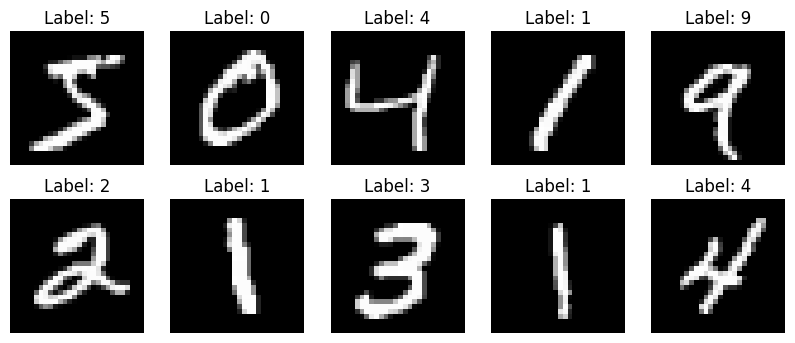

In [17]:
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")
plt.show()

## Step 4: Data Preprocessing
- Normalized pixel values from 0-255 to 0-1
- Reshaped images to (28, 28, 1) so they can be fed to the CNN

In [18]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = np.expand_dims(x_train, -1)   # (60000, 28, 28, 1)
x_test = np.expand_dims(x_test, -1)

print(x_train.shape)

(60000, 28, 28, 1)


## Step 5: Build the CNN Model
- 2 x (Conv2D + MaxPooling) layers to extract features
- Flatten, Dropout (0.3) to reduce overfitting
- Dense layer (128) and softmax output layer (10 classes)
- Optimizer: Adam, Loss: sparse categorical crossentropy

In [19]:
model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
])

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)                    │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

## Step 6: Train the Model
Trained for 5 epochs with batch size 128, using 10% of training data for validation.

In [ ]:
history = model.fit(x_train, y_train,
                    epochs=5,
                    batch_size=128,
                    validation_split=0.1)

Epoch 1/5
403/422 ━━━━━━━━━━━━━━━━━━━━ 3s 171ms/step - accuracy: 0.9285 - loss: 0.2387

## Step 7: Evaluate on Test Data
Checking accuracy on 10,000 unseen test images.

In [ ]:
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"Test Accuracy: {test_acc:.4f}")

## Step 8: Accuracy and Loss Curves
Training vs validation accuracy and loss across epochs.

In [ ]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.show()

## Step 9: Confusion Matrix and Classification Report
Shows which digits the model predicts correctly and which it confuses.

In [ ]:
y_pred = np.argmax(model.predict(x_test), axis=1)

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print(classification_report(y_test, y_pred))

## Step 10: Sample Predictions
Green title = correct prediction, red title = wrong prediction.

In [ ]:
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap="gray")
    color = "green" if y_pred[i] == y_test[i] else "red"
    plt.title(f"Pred: {y_pred[i]}\nTrue: {y_test[i]}", color=color)
    plt.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
## Conclusion

- Built a CNN (2 Conv2D + MaxPooling layers, Dropout, Dense layers) to recognize handwritten digits from the MNIST dataset.
- **Test Accuracy: 99.03%** (Test Loss: 0.0290) on 10,000 unseen images, after only 5 epochs.
- Final epoch: Training Accuracy 98.88%, Validation Accuracy 99.10%. Training and validation curves are close, so the model is not overfitting.
- The classification report shows precision, recall and F1-score of about 0.98-1.00 for every digit.
- Digit 9 had the lowest recall (0.97) and was mostly confused with 7 and 8. Some 2s were confused with 7, and some 6s with 0, because these digits can look similar when handwritten.
- CNN works well for images because it automatically learns patterns like edges and shapes.